In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, classification_report
from catboost import CatBoostClassifier, Pool

pd.set_option("display.max_columns", None)
RANDOM_STATE = 42

In [39]:
df = pd.read_csv("./data/train.csv")
df.shape

(786431, 18)

## 1. EDA

In [40]:
df.head()

,transaction_time,merch,cat_id,amount,name_1,name_2,gender,street,one_city,us_state,post_code,lat,lon,population_city,jobs,merchant_lat,merchant_lon,target
0,2019-12-27 15:21,fraud_Cormier LLC,health_fitness,148.04,Daniel,Martinez,M,8510 Acevedo Burgs,Kent,OR,97033,45.0838,-120.6649,60,Museum education officer,45.042827,-120.709327,0
1,2019-04-17 23:09,"fraud_Brown, Homenick and Lesch",health_fitness,39.40,Grace,Williams,F,28812 Charles Mill Apt. 628,Plantersville,AL,36758,32.6176,-86.9475,1412,Drilling engineer,31.872266,-87.828247,0
2,2019-09-23 15:02,fraud_Ruecker-Mayert,kids_pets,52.96,Kyle,Park,M,7507 Larry Passage Suite 859,Mount Perry,OH,43760,39.8788,-82.1880,1831,Barrister's clerk,40.010874,-81.841249,0
3,2019-05-13 16:00,"fraud_Mante, Luettgen and Hackett",health_fitness,7.66,Monique,Martin,F,68276 Matthew Springs,Ratcliff,TX,75858,31.3833,-95.0619,43,"Engineer, production",30.888406,-95.141609,0
4,2019-08-18 07:27,fraud_Luettgen PLC,gas_transport,51.59,Christine,Johnson,F,8011 Chapman Tunnel Apt. 568,Blairsden-Graeagle,CA,96103,39.8127,-120.6405,1725,Chartered legal executive (England and Wales),39.376017,-121.311691,0


In [41]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 786431 entries, 0 to 786430
Data columns (total 18 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   transaction_time  786431 non-null  str    
 1   merch             786431 non-null  str    
 2   cat_id            786431 non-null  str    
 3   amount            786431 non-null  float64
 4   name_1            786431 non-null  str    
 5   name_2            786431 non-null  str    
 6   gender            786431 non-null  str    
 7   street            786431 non-null  str    
 8   one_city          786431 non-null  str    
 9   us_state          786431 non-null  str    
 10  post_code         786431 non-null  int64  
 11  lat               786431 non-null  float64
 12  lon               786431 non-null  float64
 13  population_city   786431 non-null  int64  
 14  jobs              786431 non-null  str    
 15  merchant_lat      786431 non-null  float64
 16  merchant_lon      786431 non-nu

In [42]:
df["target"].value_counts()


target
0    781927
1      4504
Name: count, dtype: int64

In [43]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
amount,786431.0,70.241296,161.091489,1.000000,9.650000,47.410000,83.000000,2.739012e+04
post_code,786431.0,48802.521336,26896.564152,1257.000000,26237.000000,48174.000000,72042.000000,9.978300e+04
lat,786431.0,38.527972,5.078756,20.027100,34.620500,39.346500,41.894800,6.669330e+01
lon,786431.0,-90.224069,13.754760,-165.672300,-96.798000,-87.476900,-80.158000,-6.795030e+01
population_city,786431.0,89288.530335,302860.007129,23.000000,743.000000,2456.000000,20478.000000,2.906700e+06
merchant_lat,786431.0,38.527301,5.113222,19.027804,34.727480,39.357665,41.950609,6.744152e+01
merchant_lon,786431.0,-90.224508,13.766977,-166.670132,-96.901593,-87.436919,-80.233429,-6.695600e+01
target,786431.0,0.005727,0.075461,0.000000,0.000000,0.000000,0.000000,1.000000e+00


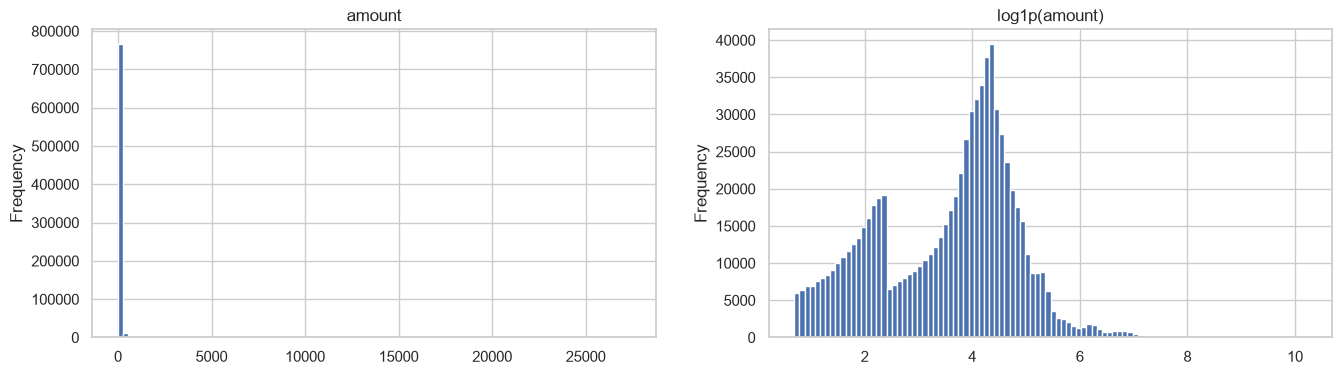

In [44]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
df["amount"].plot(kind="hist", bins=100, ax=ax[0], title="amount")
np.log1p(df["amount"]).plot(kind="hist", bins=100, ax=ax[1], title="log1p(amount)")
plt.show()

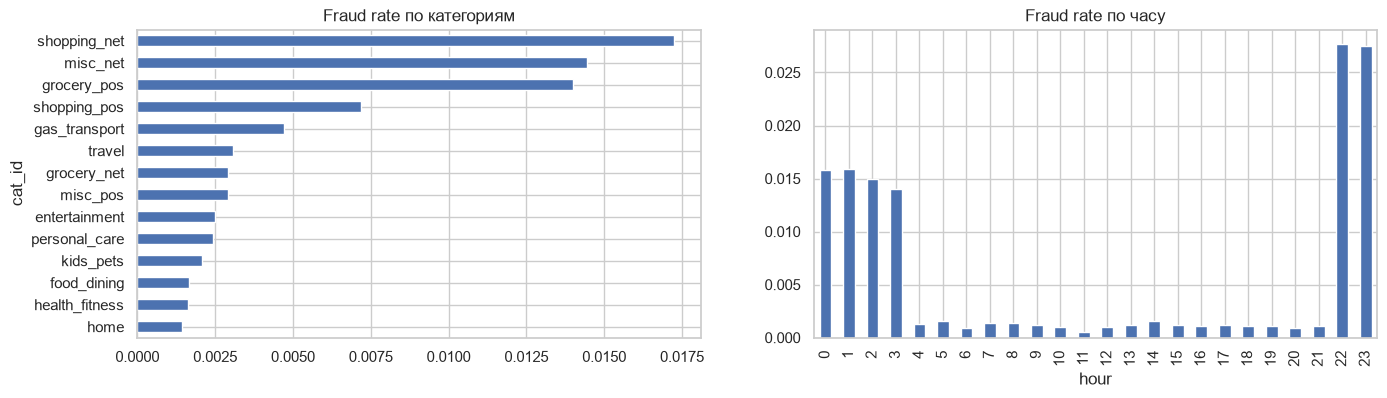

In [24]:
df["hour"] = pd.to_datetime(df["transaction_time"]).dt.hour
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
df.groupby("cat_id")["target"].mean().sort_values().plot(kind="barh", ax=ax[0], title="Fraud rate по категориям")
df.groupby("hour")["target"].mean().plot(kind="bar", ax=ax[1], title="Fraud rate по часу")
plt.show()
df.drop(columns="hour", inplace=True)

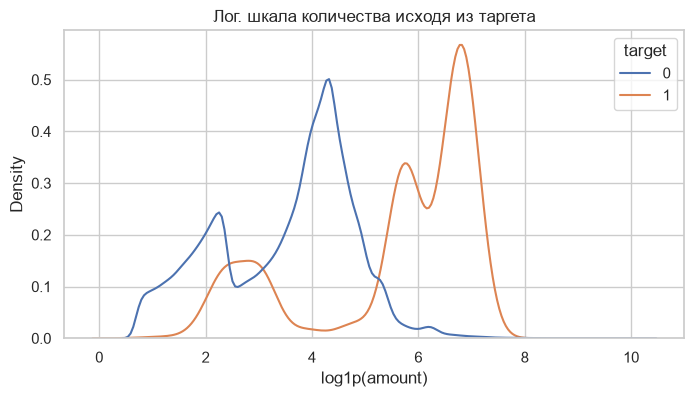

In [45]:
plt.figure(figsize=(8, 4))
sns.kdeplot(data=df, x=np.log1p(df["amount"]), hue="target", common_norm=False)
plt.title("Лог. шкала количества исходя из таргета")
plt.xlabel("log1p(amount)"); 
plt.show()

## 2. Feature engineering

In [46]:
def distance(lat1, lon1, lat2, lon2):
    R = 6371
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return R * 2 * np.arcsin(np.sqrt(a))


def add_features(data):
    data = data.copy()
    t = pd.to_datetime(data["transaction_time"])
    data["hour"] = t.dt.hour
    data["dayofweek"] = t.dt.dayofweek
    data["day"] = t.dt.day
    data["month"] = t.dt.month
    data["is_night"] = ((t.dt.hour < 3) | (t.dt.hour >= 22)).astype(int)

    data["amount_log"] = np.log1p(data["amount"])
    data["population_log"] = np.log1p(data["population_city"])
    data["distance_km"] = distance(data["lat"], data["lon"], data["merchant_lat"], data["merchant_lon"])
    return data

In [47]:
NUM_FEATURES = [
    "amount", "amount_log", "population_city", "population_log", "distance_km",
    "lat", "lon", "merchant_lat", "merchant_lon",
    "hour", "dayofweek", "day", "month", "is_night",
]
CAT_FEATURES = [
    "merch", "cat_id", "gender", "us_state", "jobs",
    "name_1", "name_2", "one_city", "street", "post_code",
]
FEATURES = NUM_FEATURES + CAT_FEATURES
TARGET = "target"


def build_X(data):
    data = add_features(data)
    X = data[FEATURES].copy()
    X[CAT_FEATURES] = X[CAT_FEATURES].astype(str)
    return X


X = build_X(df)
y = df[TARGET]
X.shape

(786431, 24)

## 3. Обучение CatBoost

In [49]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("train:", X_train.shape, "fraud:", y_train.mean().round(4))
print("val:  ", X_val.shape, "fraud:", y_val.mean().round(4))

train: (629144, 24) fraud: 0.0057
val:   (157287, 24) fraud: 0.0057


In [52]:
train_pool = Pool(X_train, y_train, cat_features=CAT_FEATURES)
val_pool = Pool(X_val, y_val, cat_features=CAT_FEATURES)

model = CatBoostClassifier(
    iterations=1500,
    learning_rate=0.05,
    depth=5,
    l2_leaf_reg=3.0,
    loss_function="Logloss",
    eval_metric="AUC",
    auto_class_weights="Balanced",
    random_seed=RANDOM_STATE,
    early_stopping_rounds=100,
    task_type="CPU",
    verbose=100,
)
model.fit(train_pool, eval_set=val_pool)

0:	test: 0.9692708	best: 0.9692708 (0)	total: 206ms	remaining: 5m 9s
100:	test: 0.9936356	best: 0.9936356 (100)	total: 17.2s	remaining: 3m 58s
200:	test: 0.9957547	best: 0.9957572 (198)	total: 36.8s	remaining: 3m 58s
300:	test: 0.9970016	best: 0.9970016 (300)	total: 56.5s	remaining: 3m 45s
400:	test: 0.9975131	best: 0.9975131 (400)	total: 1m 14s	remaining: 3m 25s
500:	test: 0.9977850	best: 0.9977914 (498)	total: 1m 33s	remaining: 3m 7s
600:	test: 0.9980307	best: 0.9980307 (600)	total: 1m 53s	remaining: 2m 50s
700:	test: 0.9981356	best: 0.9981379 (699)	total: 2m 13s	remaining: 2m 32s
800:	test: 0.9983050	best: 0.9983078 (798)	total: 2m 34s	remaining: 2m 14s
900:	test: 0.9983692	best: 0.9983701 (889)	total: 2m 55s	remaining: 1m 56s
1000:	test: 0.9984611	best: 0.9984641 (997)	total: 3m 16s	remaining: 1m 37s
1100:	test: 0.9985516	best: 0.9985516 (1100)	total: 3m 37s	remaining: 1m 18s
1200:	test: 0.9986125	best: 0.9986201 (1199)	total: 3m 58s	remaining: 59.3s
1300:	test: 0.9986744	best: 0.9

CatBoostClassifier(auto_class_weights='Balanced', depth=5, early_stopping_rounds=100, eval_metric='AUC', iterations=1500, l2_leaf_reg=3.0, learning_rate=0.05, loss_function='Logloss', random_seed=42, task_type='CPU', verbose=100)

In [53]:
val_proba = model.predict_proba(X_val)[:, 1]
print(f"ROC-AUC: {roc_auc_score(y_val, val_proba):.4f}")
print(f"PR-AUC : {average_precision_score(y_val, val_proba):.4f}")

ROC-AUC: 0.9987
PR-AUC : 0.9346


## 4. Подбор порога

In [54]:
thresholds = np.linspace(0.05, 0.95, 100)
f1s = [f1_score(y_val, (val_proba >= t).astype(int)) for t in thresholds]
best_t = thresholds[int(np.argmax(f1s))]
print(f"Лучший порог по F1: {best_t}  (F1={max(f1s)})")

Лучший порог по F1: 0.95  (F1=0.882830626450116)


In [55]:
model.save_model("fraude_detector/models/catboost_fraud.cbm")